In [1]:
FIRST_NAME = "Indhuja"
LAST_NAME = "Gudluru"
STUDENT_ID = "801366046"

In [2]:
# Extra imports for this lab that are beyond the scope of discussion
import os
import gc
import traceback
import warnings
from pdb import set_trace

# Set this to True if you DO NOT want to run the 
# garbage_collect() functions throughout the notebook
turn_off_garbage_collect = False

def garbage_collect(vars_):
    if not turn_off_garbage_collect:
        for v in vars_:
            if v in globals():
                del globals()[v]
        collected = gc.collect()

        
class TodoCheckFailed(Exception):
    pass

def todo_check(asserts):
    failed_err = "You passed {}/{} and FAILED the following code checks:\n{}"
    failed = ""
    n_failed = 0
    for check, (condi, err) in enumerate(asserts):
        exc_failed = False
        if isinstance(condi, str):
            try:
                passed = eval(condi)
            except Exception:
                exc_failed = True
                n_failed += 1
                failed += f"\nCheck [{check+1}]: Failed to execute check [{check+1}] due to the following error...\n{traceback.format_exc()}"
        elif isinstance(condi, bool):
            passed = condi
        else:
            raise ValueError("asserts must be a list of strings or bools")

        if not exc_failed and not passed:
            n_failed += 1
            failed += f"\nCheck [{check+1}]: Failed\n\tTip: {err}\n"

    if len(failed) != 0:
        passed = len(asserts) - n_failed
        err = failed_err.format(passed, len(asserts), failed)
        raise TodoCheckFailed(err.format(failed))
    print("Your code PASSED the code check!")

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
from copy import deepcopy as copy
from sklearn.neighbors import KNeighborsClassifier
%matplotlib inline

In [4]:
import sklearn
sklearn.__version__

'1.4.0'

In [5]:
from sklearn import datasets, neighbors           # 1) import

X, t = datasets.load_digits(return_X_y=True)      # 2) prepare data (from library embeded one)
X = X / X.max()                                   #.     - rescale the X to betweeen 0 and 1

# number of data samples
N = X.shape[0]

# prepare train and test data
i_split = int(0.8 * N)
X_train = X[:i_split]
t_train = t[:i_split]
X_test = X[i_split:]
t_test = t[i_split:]

knn = neighbors.KNeighborsClassifier()            # 3) initialize - create an KNN classifier using default setting

knn.fit(X_train, t_train)                         # 4) train with training data (input, X_train and target, t_train)

knn.score(X_test, t_test)                         # 5) evaluate the model on the entire test data and compute the accuracy


0.9638888888888889

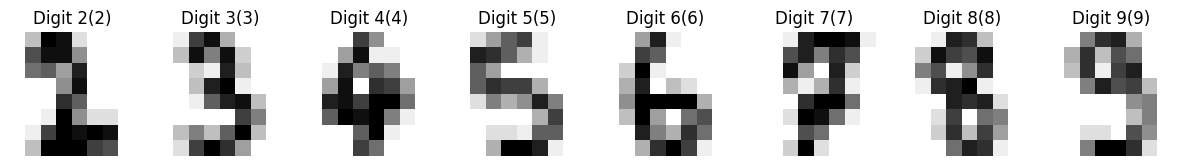

In [6]:
k = 8  # the number of data samples to check

y = knn.predict(X_test[0:k])                     # 5) predict - for the first k data samples in X_test

# plot the digits along with "label (prediction)"
_, axes = plt.subplots(1, k, figsize=(15,3))
for ax, image, label, pred in zip(axes, X_test[:k], t_test[:k], y):
    
    ax.set_axis_off()
    ax.imshow(image.reshape((8,8)), cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Digit {}({})'.format(label, pred))

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
from sklearn import linear_model

%matplotlib inline

In [8]:
# TODO 1-1: 
%pfile data.csv

Object `data.csv` not found.


normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,4,130,mpfi,3.47,2.68,9,111,5000,21,27,13495,3
NaN,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,4,130,mpfi,3.47,2.68,9,111,5000,21,27,16500,3
NaN,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,6,152,mpfi,2.68,3.47,9,154,5000,19,26,16500,1
164,audi,gas,std,4,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,4,109,mpfi,3.19,3.4,10,102,5500,24,30,13950,2
164,audi,gas,std,4,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,5,136,mpfi,3.19,3.4,8,115,5500,18,22,17450,2
NaN,audi,gas,std,2,sedan,fwd,front,99.8,177.3,66.3,53.1,2507,ohc,5,136,mpfi,3.19,3.4,8.5,110,5500,19,25,15250,2
158,audi,gas,s

In [9]:
df = pd.read_csv('data.csv')
df

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
0,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,3
1,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,3
2,NaN,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,171.2,...,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,1
3,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,176.6,...,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,2
4,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,176.6,...,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,95.0,volvo,gas,std,4.0,sedan,rwd,front,109.1,188.8,...,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0,-1
201,95.0,volvo,gas,turbo,4.0,sedan,rwd,front,109.1,188.8,...,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0,-1
202,95.0,volvo,gas,std,4.0,sedan,rwd,front,109.1,188.8,...,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0,-1
203,95.0,volvo,diesel,turbo,4.0,sedan,rwd,front,109.1,188.8,...,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0,-1


In [10]:
df_describe = df.describe()
df_describe

,normalized-losses,num-of-doors,wheel-base,length,width,height,curb-weight,num-of-cylinders,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
count,164.000000,203.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,201.000000,201.000000,205.000000,203.000000,203.000000,205.000000,205.000000,201.000000,205.000000
mean,122.000000,3.123153,98.756585,174.049268,65.907805,53.724878,2555.565854,4.380488,126.907317,3.329751,3.255423,10.142537,104.256158,5125.369458,25.219512,30.751220,13207.129353,0.834146
std,35.442168,0.994841,6.021776,12.337289,2.145204,2.443522,520.680204,1.080854,41.642693,0.273539,0.316717,3.972040,39.714369,479.334560,6.542142,6.886443,7947.066342,1.245307
min,65.000000,2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,2.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,-2.000000
25%,94.000000,2.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,4.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,0.000000
50%,115.000000,4.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,4.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000,1.000000
75%,150.000000,4.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,4.000000,141.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,2.000000
max,256.000000,4.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,12.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000,3.000000


In [11]:
# Check for any null data in the dataset
null_df = df.isnull()

any_nulls = np.any(null_df)
any_nulls


True

In [12]:
# Print the rows with null data
rows_with_null = df[null_df.any(axis=1)]
rows_with_null

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
0,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,3
1,NaN,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,3
2,NaN,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,171.2,...,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,1
5,NaN,audi,gas,std,2.0,sedan,fwd,front,99.8,177.3,...,mpfi,3.19,3.40,8.5,110.0,5500.0,19,25,15250.0,2
7,NaN,audi,gas,std,4.0,wagon,fwd,front,105.8,192.7,...,mpfi,3.19,3.40,8.5,110.0,5500.0,19,25,18920.0,1
9,NaN,audi,gas,turbo,2.0,hatchback,4wd,front,99.5,178.2,...,mpfi,3.13,3.40,7.0,160.0,5500.0,16,22,NaN,0
14,NaN,bmw,gas,std,4.0,sedan,rwd,front,103.5,189.0,...,mpfi,3.31,3.19,9.0,121.0,4250.0,20,25,24565.0,1
15,NaN,bmw,gas,std,4.0,sedan,rwd,front,103.5,189.0,...,mpfi,3.62,3.39,8.0,182.0,5400.0,16,22,30760.0,0
16,NaN,bmw,gas,std,2.0,sedan,rwd,front,103.5,193.8,...,mpfi,3.62,3.39,8.0,182.0,5400.0,16,22,41315.0,0
17,NaN,bmw,gas,std,4.0,sedan,rwd,front,110.0,197.0,...,mpfi,3.62,3.39,8.0,182.0,5400.0,15,20,36880.0,0


In [13]:
from sklearn.impute import SimpleImputer

# TODO 2:
imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

# Fit the imputer on the data and transform it
df_freq = pd.DataFrame(imp.fit_transform(df), columns=df.columns)
df_freq.head

<bound method NDFrame.head of     normalized-losses         make fuel-type aspiration num-of-doors  \
0               161.0  alfa-romero       gas        std          2.0   
1               161.0  alfa-romero       gas        std          2.0   
2               161.0  alfa-romero       gas        std          2.0   
3               164.0         audi       gas        std          4.0   
4               164.0         audi       gas        std          4.0   
..                ...          ...       ...        ...          ...   
200              95.0        volvo       gas        std          4.0   
201              95.0        volvo       gas      turbo          4.0   
202              95.0        volvo       gas        std          4.0   
203              95.0        volvo    diesel      turbo          4.0   
204              95.0        volvo       gas      turbo          4.0   

      body-style drive-wheels engine-location wheel-base length  ...  \
0    convertible          rwd    

In [14]:
df_freq.columns = df.columns
df_freq.head()

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
0,161.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,3
1,161.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,3
2,161.0,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,171.2,...,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,1
3,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,176.6,...,mpfi,3.19,3.4,10.0,102.0,5500.0,24,30,13950.0,2
4,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,176.6,...,mpfi,3.19,3.4,8.0,115.0,5500.0,18,22,17450.0,2


In [15]:
df = df_freq
df.head()

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
0,161.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,3
1,161.0,alfa-romero,gas,std,2.0,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,3
2,161.0,alfa-romero,gas,std,2.0,hatchback,rwd,front,94.5,171.2,...,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,1
3,164.0,audi,gas,std,4.0,sedan,fwd,front,99.8,176.6,...,mpfi,3.19,3.4,10.0,102.0,5500.0,24,30,13950.0,2
4,164.0,audi,gas,std,4.0,sedan,4wd,front,99.4,176.6,...,mpfi,3.19,3.4,8.0,115.0,5500.0,18,22,17450.0,2


In [16]:
df.dtypes

normalized-losses    object
make                 object
fuel-type            object
aspiration           object
num-of-doors         object
body-style           object
drive-wheels         object
engine-location      object
wheel-base           object
length               object
width                object
height               object
curb-weight          object
engine-type          object
num-of-cylinders     object
engine-size          object
fuel-system          object
bore                 object
stroke               object
compression-ratio    object
horsepower           object
peak-rpm             object
city-mpg             object
highway-mpg          object
price                object
symboling            object
dtype: object

In [17]:
numeric_columns = ['normalized-losses', 'num-of-doors', 'wheel-base', 'length', 'width', 'height', 
                   'curb-weight', 'num-of-cylinders', 'engine-size', 'bore', 'stroke', 'compression-ratio', 
                   'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'symboling']

df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

df.dtypes

normalized-losses    float64
make                  object
fuel-type             object
aspiration            object
num-of-doors         float64
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders       int64
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
symboling              int64
dtype: object

In [18]:
strings_list = ['make', 'fuel-type', 'aspiration', 'body-style', 
                'drive-wheels', 'engine-location', 'engine-type', 'fuel-system']

from sklearn import preprocessing

# TODO 3:
# Initialize a LabelEncoder
label_encoder = preprocessing.LabelEncoder()

# Convert each column's string data to integer format
for column in strings_list:
    df[column] = label_encoder.fit_transform(df[column])
    


In [19]:
df.dtypes

normalized-losses    float64
make                   int32
fuel-type              int32
aspiration             int32
num-of-doors         float64
body-style             int32
drive-wheels           int32
engine-location        int32
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type            int32
num-of-cylinders       int64
engine-size            int64
fuel-system            int32
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
symboling              int64
dtype: object

In [20]:
df

,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,symboling
0,161.0,0,1,0,2.0,0,2,0,88.6,168.8,...,5,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,3
1,161.0,0,1,0,2.0,0,2,0,88.6,168.8,...,5,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,3
2,161.0,0,1,0,2.0,2,2,0,94.5,171.2,...,5,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,1
3,164.0,1,1,0,4.0,3,1,0,99.8,176.6,...,5,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,2
4,164.0,1,1,0,4.0,3,0,0,99.4,176.6,...,5,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,95.0,21,1,0,4.0,3,2,0,109.1,188.8,...,5,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0,-1
201,95.0,21,1,1,4.0,3,2,0,109.1,188.8,...,5,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0,-1
202,95.0,21,1,0,4.0,3,2,0,109.1,188.8,...,5,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0,-1
203,95.0,21,0,1,4.0,3,2,0,109.1,188.8,...,3,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0,-1


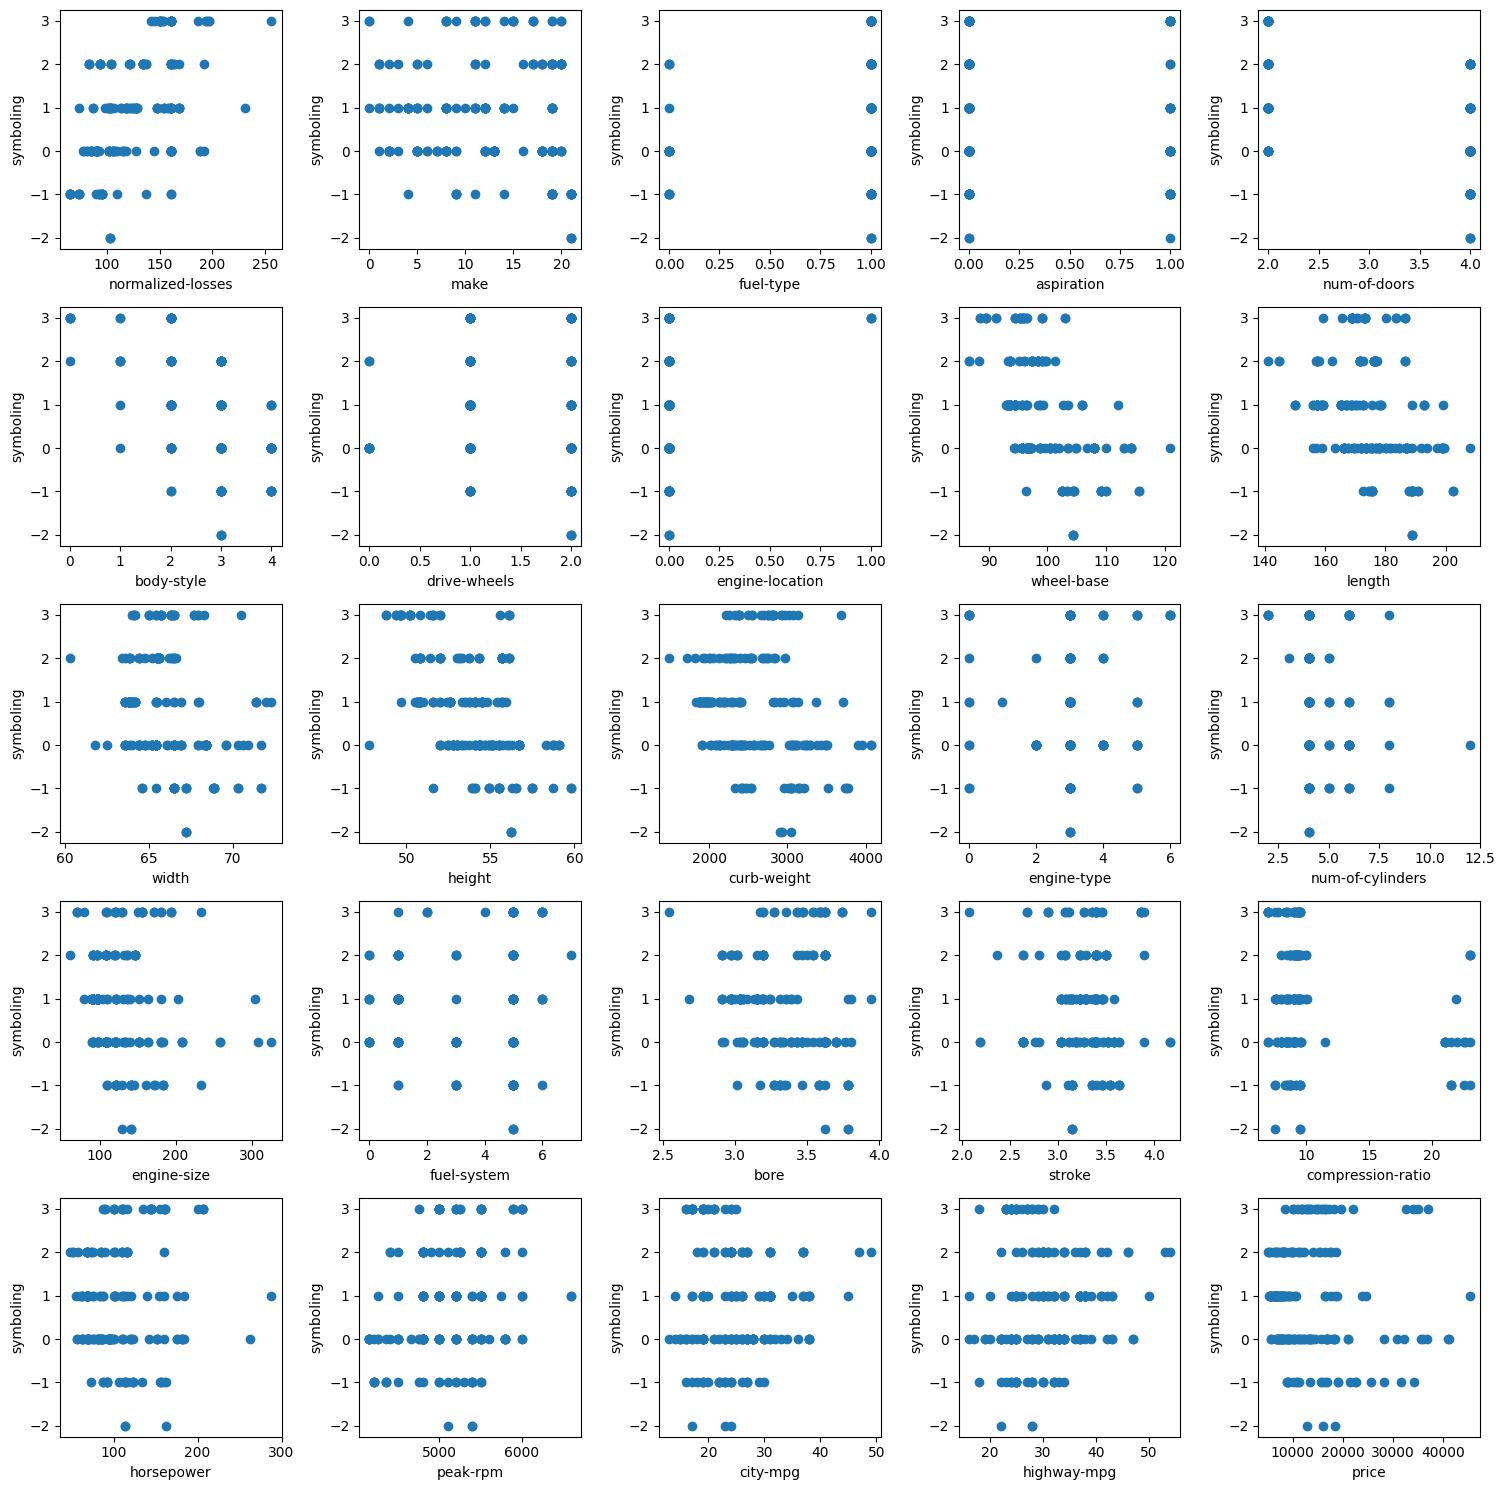

In [21]:

# Create a list of column names to plot against 'symboling', excluding 'symboling' itself
features_to_plot = [col for col in df.columns if col != 'symboling']

fig = plt.figure(figsize=(15, 15))  # Adjust figsize if needed
plt.clf()  # Clear the previous plt figure

# Loop through the features and create scatter plots
for i, feature in enumerate(features_to_plot[:25]):  # Plot only the first 25 features
    plt.subplot(5, 5, i + 1)  # Selects which subplot to plot to
    plt.scatter(df[feature], df['symboling'])  # Scatter plot of feature vs target
    correlation = df[feature].corr(df['symboling'])  # Calculate the correlation coefficient
    plt.xlabel(feature)  # Sets X label
    plt.ylabel('symboling')  # Sets Y label
    plt.grid(False)

fig.tight_layout()
plt.show()



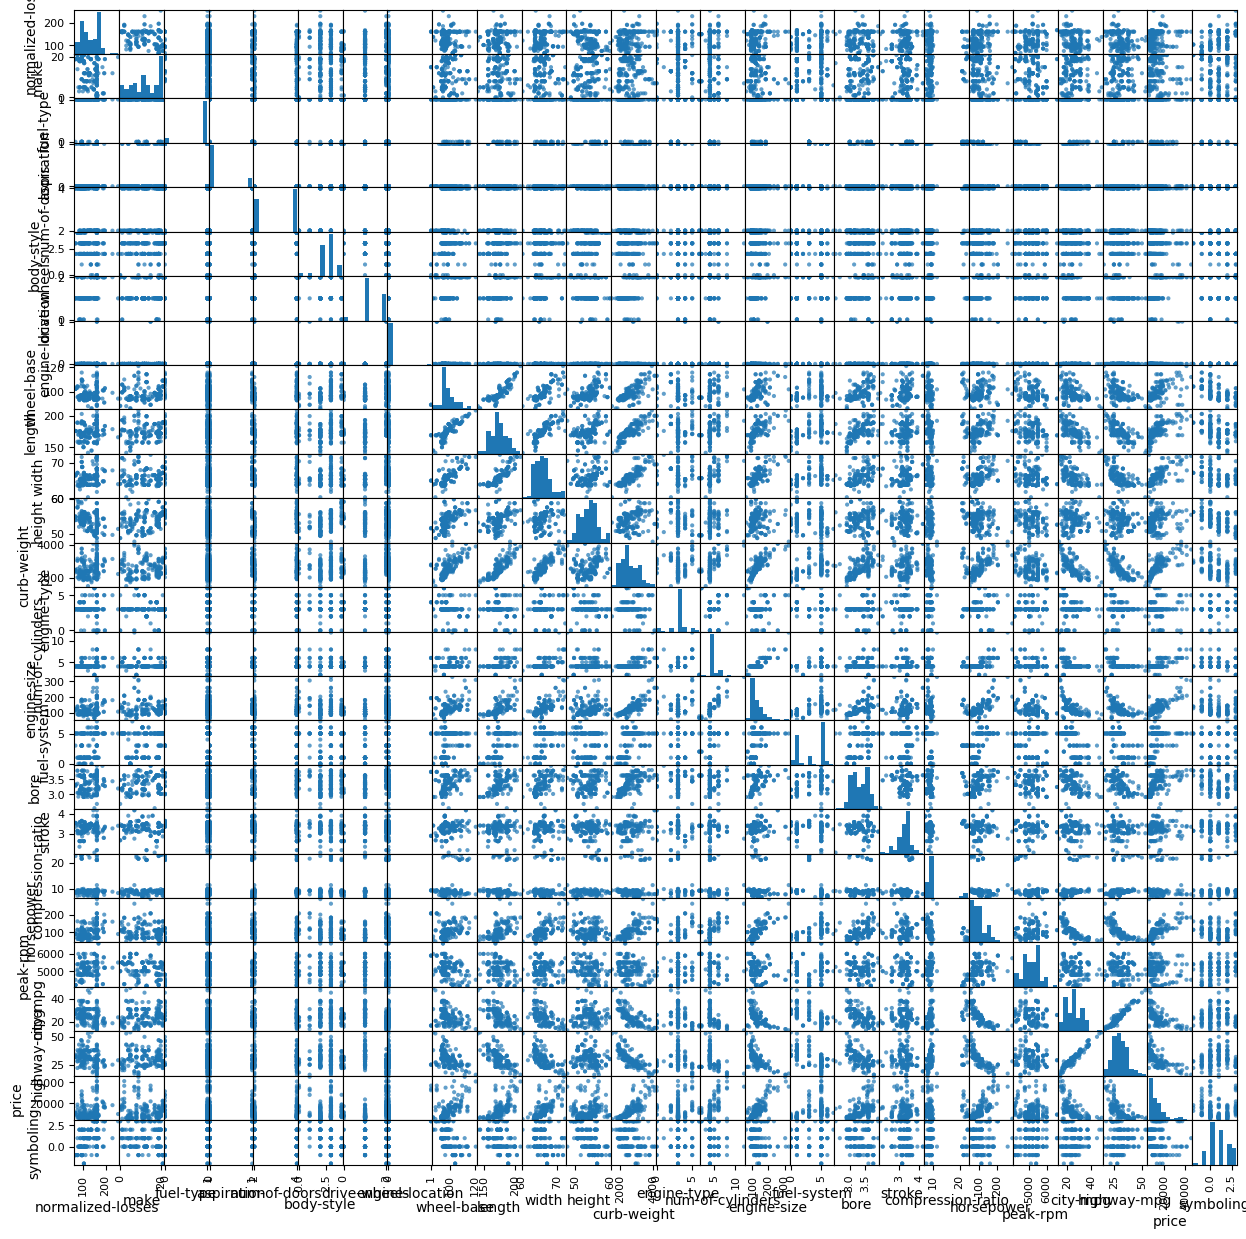

In [22]:
from pandas.plotting import scatter_matrix
scatter_matrix(df, figsize=(15, 15), alpha=0.7)
plt.show()

In [23]:
df['symboling'].unique()

array([ 3,  1,  2,  0, -1, -2], dtype=int64)

<Axes: >

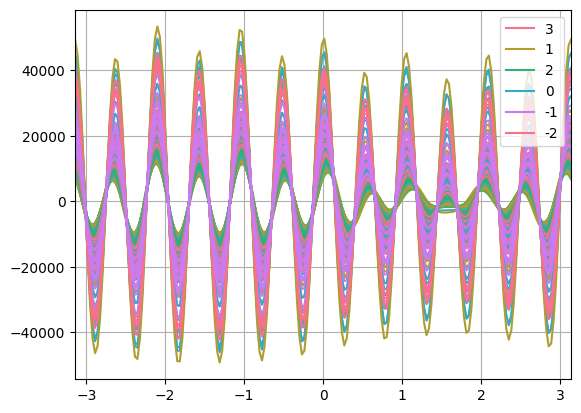

In [24]:
from pandas.plotting import andrews_curves
import seaborn as sns
# Create a color palette for different target values
palette = sns.color_palette("husl", as_cmap=True)

# Create Andrew's curves plot with different colors for target values
andrews_curves(df, 'symboling', colormap=palette)


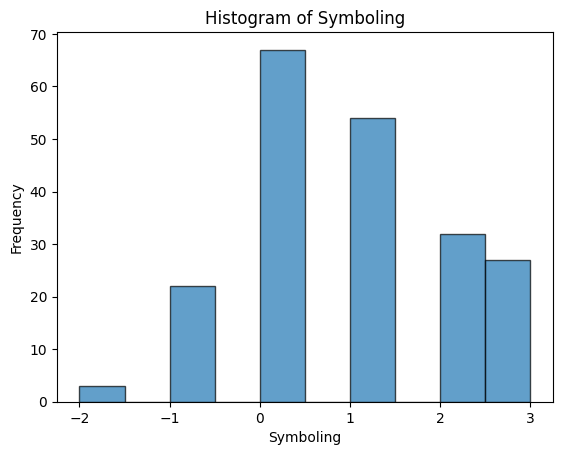

In [25]:
# Plot histogram for the 'symboling' column
plt.hist(df['symboling'], bins=10, edgecolor='k', alpha=0.7)
plt.xlabel('Symboling')
plt.ylabel('Frequency')
plt.title('Histogram of Symboling')
plt.grid(False)
plt.show()

In [26]:
# Store the target column 'symboling' into T
T = df['symboling']

# Store all the input features into X, excluding the target column 'symboling'
X = df.drop(columns=['symboling'])

# Store the total number of samples (rows) in our dataset into N
N = len(df)

In [27]:
todo_check([
    ('"X" in globals()', 'X is not defined'),
    ('np.all(np.isclose(X.iloc[10, 1:5].values, np.array([2.0, 1.0, 0.0, 2.0])))', 'X has incorrect values'),
    ('"T" in globals()', 'T is not defined'),
    ('np.all(np.isclose(T.iloc[5:10].values, np.array([2, 1, 1, 1, 0])))', 'T has incorrect values'),
    ('"N" in globals()', 'N is not defined'),
    ("N == 205", "N has the wrong value")
])

Your code PASSED the code check!


In [28]:
# TODO 5-2:
from sklearn.model_selection import train_test_split

# Split the data and targets with an 80/20 split and seed 0
X_train, X_test, t_train, t_test = train_test_split(X, T, test_size=0.2, random_state=0)

print(X.shape, X_train.shape, X_test.shape, t_train.shape, t_test.shape)

(205, 25) (164, 25) (41, 25) (164,) (41,)


In [29]:
todo_check([
    ("X_train.shape == (164, 25)", "X_train has the wrong shape"),
    ("X_test.shape == (41, 25)", "X_test has the wrong shape"),
    ("t_train.shape == (164,)", "t_train has the wrong shape"),
    ("t_test.shape == (41,)", "t_test has the wrong shape"),
])

Your code PASSED the code check!


In [30]:
from sklearn.linear_model import LinearRegression

np.random.seed(0)

# TODO 6:

# 1) initialize
model = LinearRegression()

# 2) train the model
model.fit(X_train, t_train)

# 3) evaluate
test_score = model.score(X_test, t_test)

print("Test score: ", test_score)

Test score:  0.3879966145617587


In [31]:
todo_check([
    ('np.isclose(test_score,  0.387996, rtol=.1)', '`score` potentially has the wrong value.')
])

Your code PASSED the code check!


Text(0, 0.5, 'predicted')

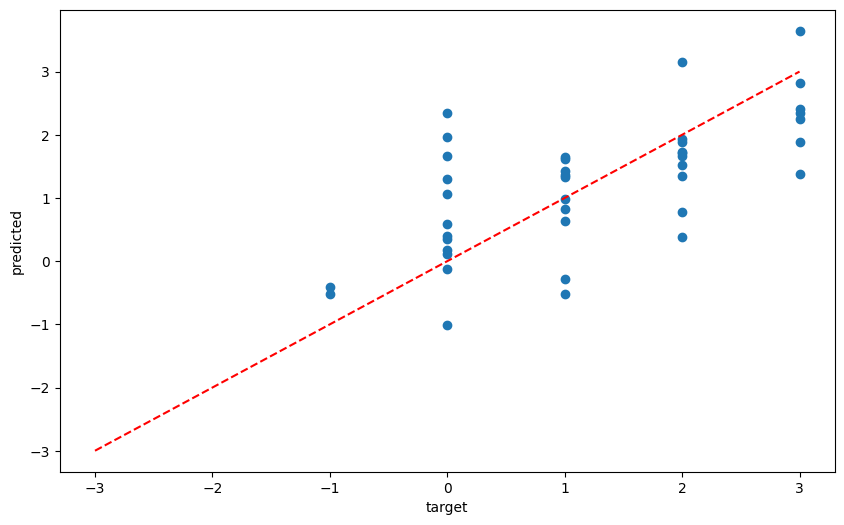

In [32]:
# TODO 7-1:

## TODO 1. make a prediction
y = model.predict(X_test)

## TODO 2. plot t_text vs y 

plt.figure(figsize=(10, 6))
plt.scatter(t_test, y)
# dashed diagonal line
plt.plot([-3,3], [-3,3], 'r--')
# x and y labels
plt.xlabel("target")
plt.ylabel("predicted")

In [33]:
todo_check([
    ("y.shape == (41,)", "y shape is incorrect"),
    ("np.all(np.isclose(y[1:5], np.array([-0.51629084, 1.938767, 1.35099362, 0.77757691])))", "y values are incorrect")
])

Your code PASSED the code check!


Text(0, 0.5, 'symboling')

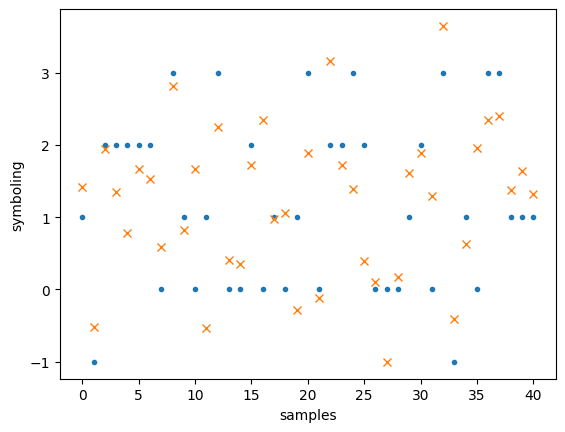

In [34]:
plt.plot(t_test.to_numpy(), '.')
plt.plot(y, 'x')
plt.xlabel("samples")
plt.ylabel("symboling")

In [35]:
t_test.unique()

array([ 1, -1,  2,  0,  3], dtype=int64)

In [36]:
print(f"t_test type {type(t_test)}")
print(f"y type {type(y)}")

t_test type <class 'pandas.core.series.Series'>
y type <class 'numpy.ndarray'>


In [37]:
uniques, counts = np.unique(t_test, return_counts=True)

print(f"Unique values in t_test: {uniques}")
print(f"Number of times each unqiue value appears in t_test: {counts}")

Unique values in t_test: [-1  0  1  2  3]
Number of times each unqiue value appears in t_test: [ 2 12 10 10  7]


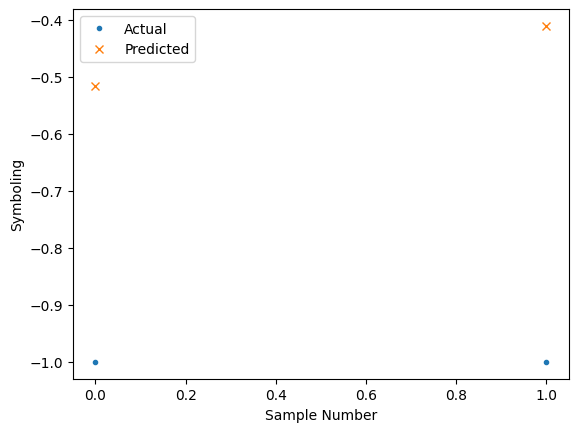

In [38]:
plt.plot(t_test.values[t_test==-1], '.', label="Actual")
plt.plot(y[t_test==-1], 'x', label="Predicted")
plt.ylabel("Symboling")
plt.xlabel("Sample Number")
plt.legend()

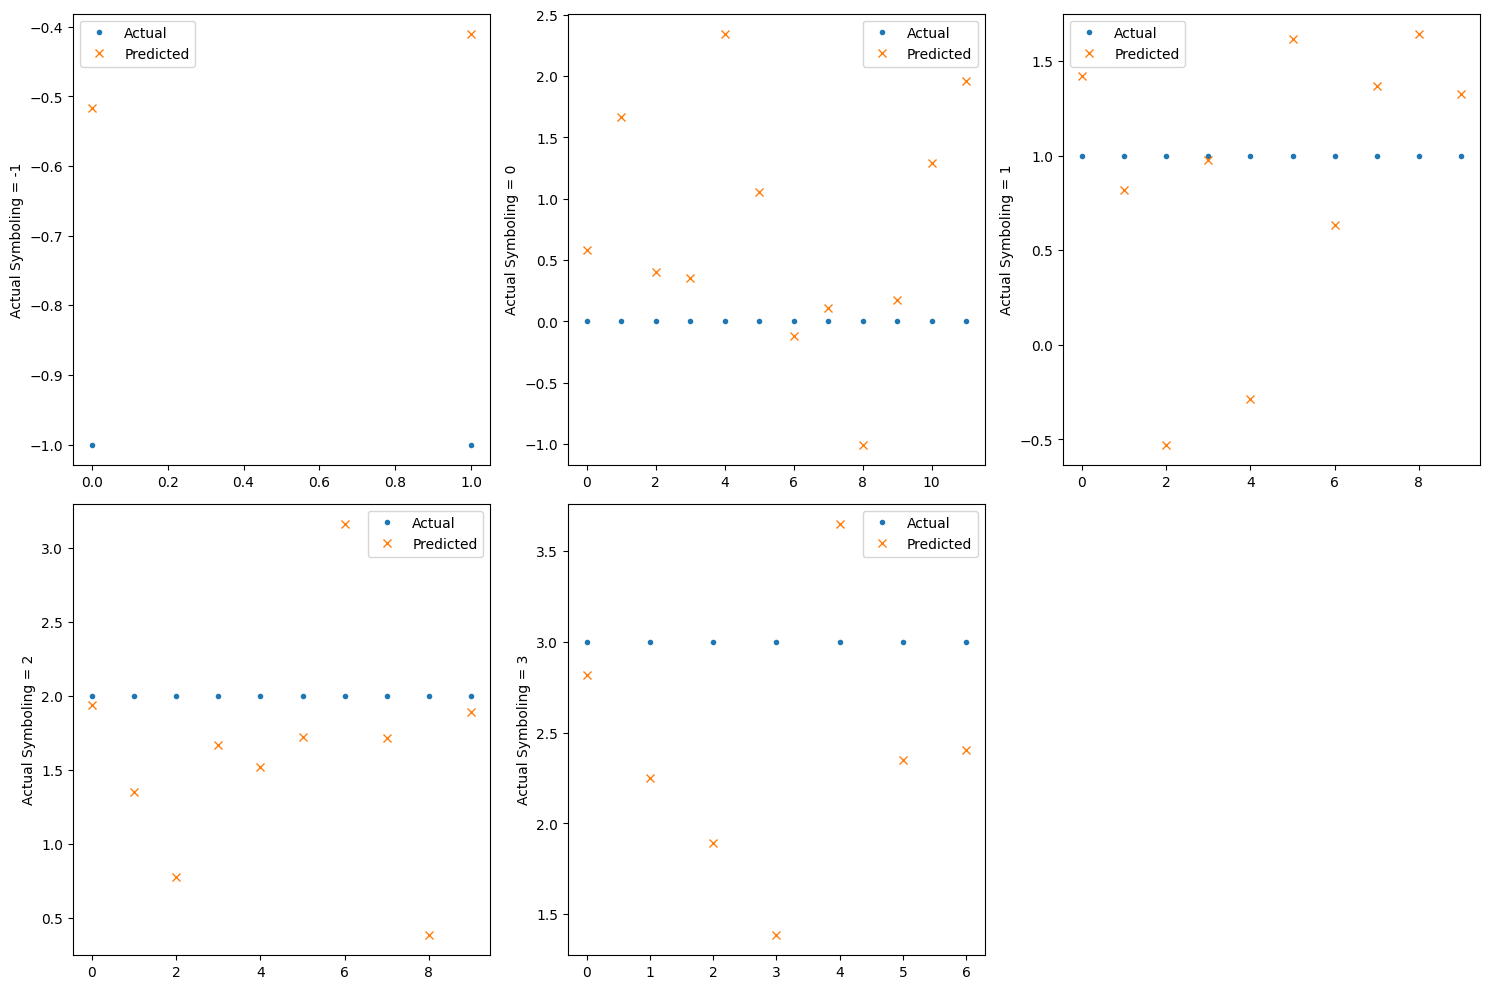

In [39]:


# Create subplots for each unique symboling value
unique_symboling = sorted(t_test.unique())

plt.figure(figsize=(15, 10))
for i, symboling_value in enumerate(unique_symboling):
    plt.subplot(2, 3, i + 1)  # Ensure that the subplots start from the first position
    actual_values = t_test[t_test == symboling_value]
    predicted_values = y[t_test == symboling_value]
    plt.plot(actual_values.values, '.', label="Actual")
    plt.plot(predicted_values, 'x', label="Predicted")
    plt.ylabel(f"Actual Symboling = {symboling_value}")
    plt.legend(['Actual', 'Predicted'])

plt.tight_layout()
plt.show()




In [40]:
def evaluate(y, t):
    plt.figure(figsize=(10,10))

    # TODO 9:
    # t vs y plot
    plt.subplot(3,3, 1)
    # TODO: add the first plot
    plt.scatter(t_test, y)
    plt.plot([-3,3], [-3,3], 'r--')
    plt.xlabel("target")
    plt.ylabel("predicted")
    plt.title('Plot-1')
    y = model.predict(X_test)
    

    # all value comparison
    plt.subplot(3,2, 2)
    # TODO: add the second one
    plt.plot(t_test.to_numpy(), '.')
    plt.plot(y, 'x')
    plt.xlabel("samples")
    plt.ylabel("symboling")
    plt.title('Plot-2')

    # subplots of individual quality comparision
    # TODO: add the third subplots
    plt.figure(figsize=(15, 8))
    for i, symboling_value in enumerate([-1, 0, 1, 2, 3]):
        plt.subplot(2, 3, i + 1)
        plt.plot(t[t == symboling_value], '.', label='Actual')
        plt.plot(y[t == symboling_value], 'x', label='Predicted')
        plt.ylabel(f'Actual Symboling = {symboling_value}')
        plt.legend()
    

    plt.legend()
    #plt.tight_layout()


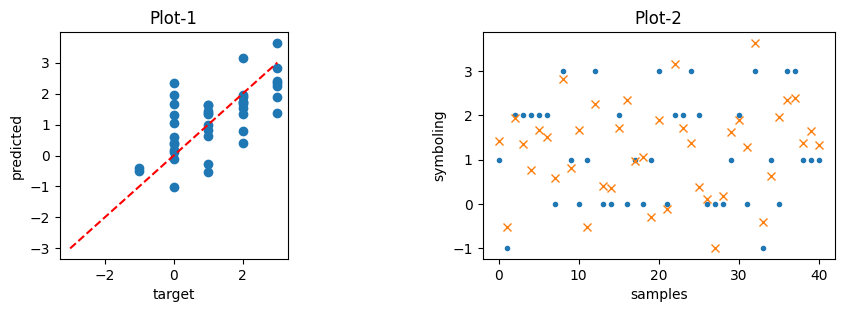

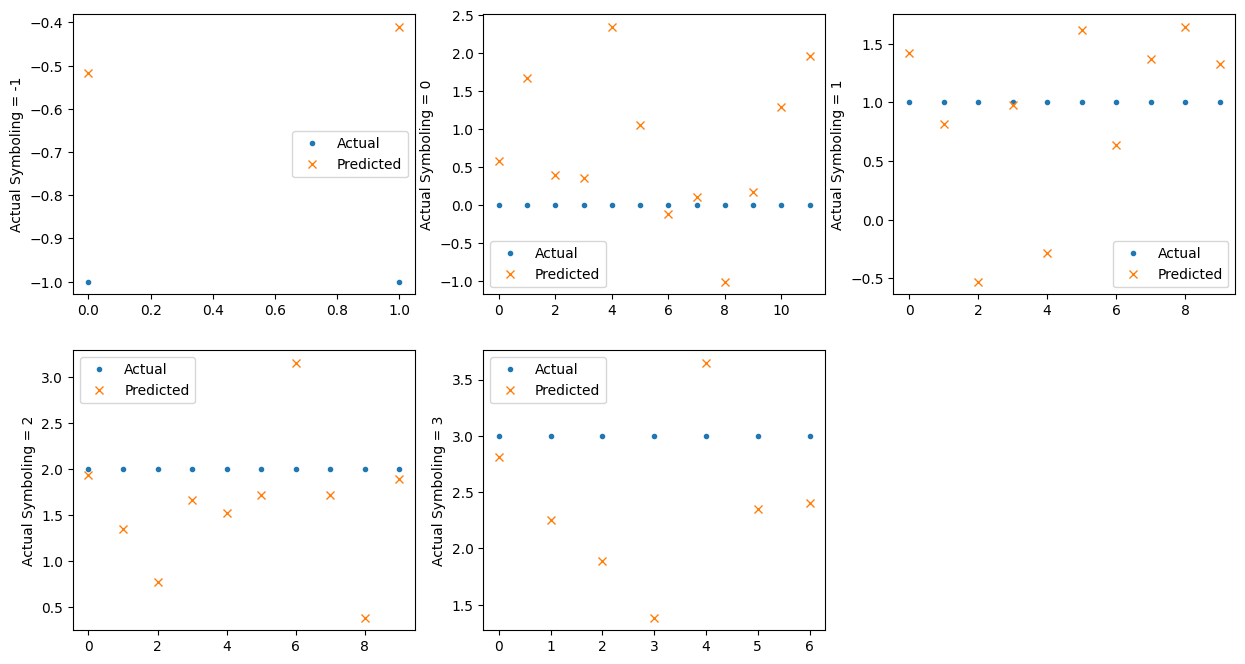

In [41]:
evaluate(y, t_test.to_numpy())

In [42]:
model.coef_

array([ 1.26736375e-02,  7.16060903e-03,  4.49154211e+00,  2.53028075e-01,
       -4.75232406e-01,  4.54172318e-02, -4.39768394e-01, -1.60714368e-01,
       -1.54654760e-01,  8.20412850e-03,  1.42359986e-01,  2.46358470e-02,
       -5.31581287e-04, -4.55048578e-02, -6.70270696e-01,  1.88724059e-02,
        6.54111688e-02, -5.71760198e-01,  9.61436623e-02,  3.37294409e-01,
       -1.02332936e-02, -2.11871124e-04, -1.07786716e-01,  5.19049770e-02,
        5.25894531e-05])

In [43]:
model.intercept_

2.683063578381711

In [44]:

# print the value text over the bar
# https://matplotlib.org/3.1.1/gallery/lines_bars_and_markers/barchart.html
def autolabel(ax, rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{:0.3f}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', color='blue')

def show_weights(model, names):
    
    # combine both the coefficients and intercept to present
    w = np.append(model.coef_, model.intercept_)
    names = list(names) + ['bias/intercept']
    

    plt.figure(figsize=(12,3))
    
    # TODO: create bar chart to present the weights
    # Ensure the lengths match
    names = names[:len(w)]
    rects = plt.bar(range(len(w)), w, color='blue')
    
    ax = plt.gca()
    ax.set_xticks(range(len(w)))
    ax.set_xticklabels(names, rotation = 90, ha='right')
    
   
    # TODO: call the autolabel function
    autolabel(ax, rects)
    plt.show()


    

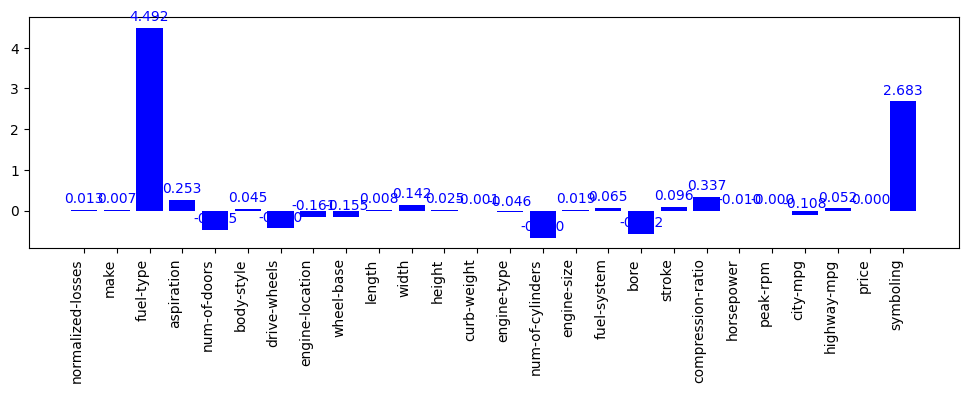

In [45]:
show_weights(model, df.columns.values)

In [46]:
from sklearn.linear_model import Ridge

# 1) initialize
model = Ridge()

# 2) train the model
model.fit(X_train, t_train)
# 3) evaluate
test_score = model.score(X_test, t_test)

print("Test score: ", test_score)

Test score:  0.38881978529755756


In [47]:
todo_check([
    ('test_score > 0.30', '`test_score` is below .30, try adusting the `alpha` value.')
])

Your code PASSED the code check!


In [48]:
# 4) Predict the values
y = model.predict(X_test)

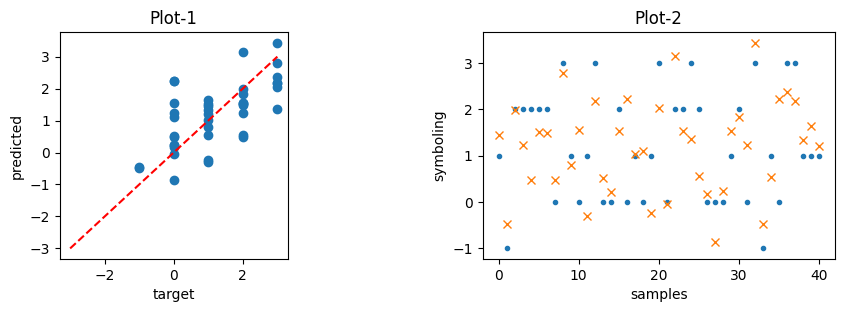

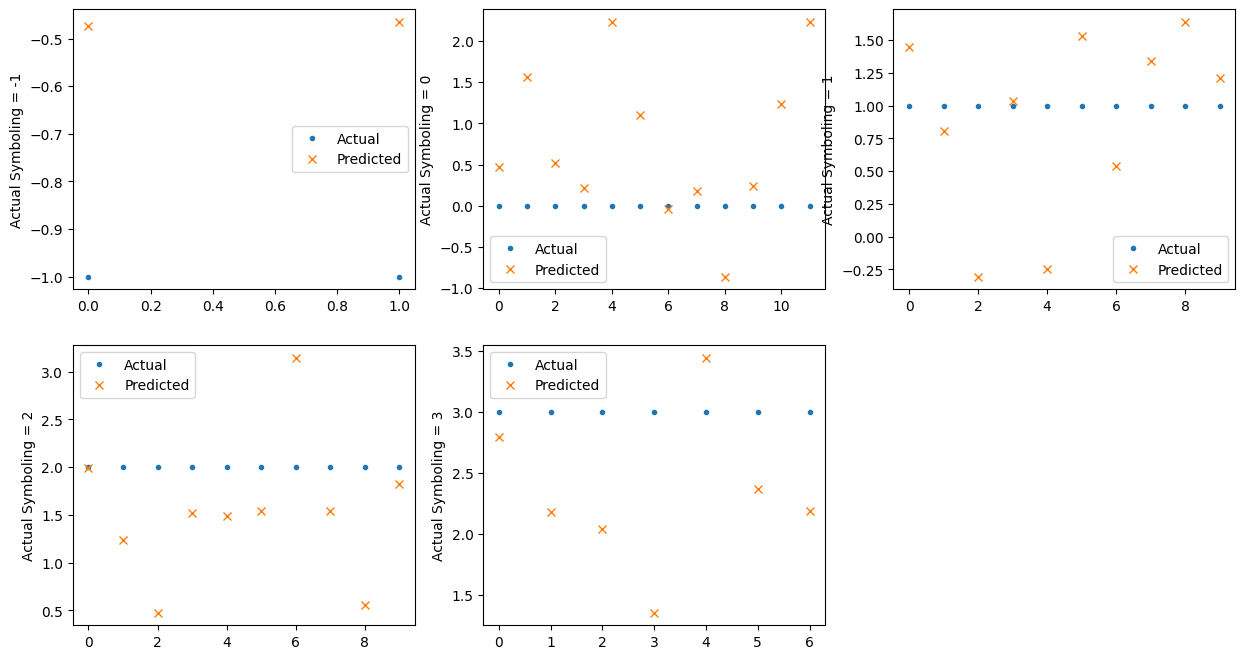

In [49]:
# 5) Plot actual vs predicted graphs
evaluate(y, t_test.to_numpy())

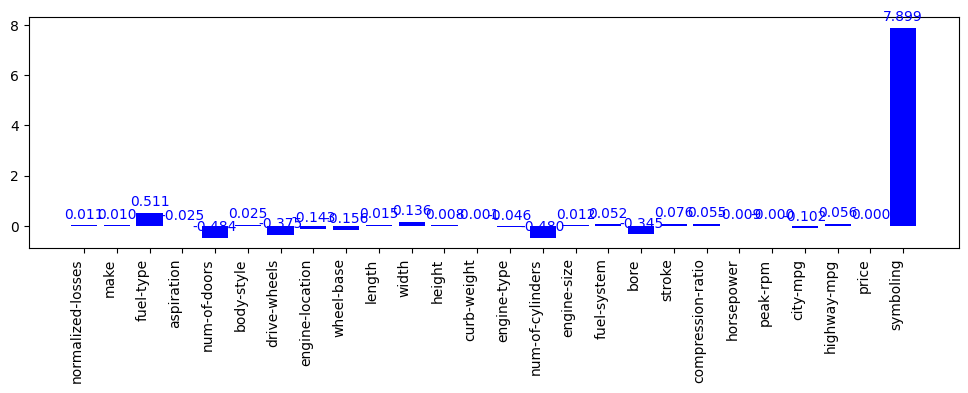

In [50]:
show_weights(model, df.columns.values)

Test score:   0.41919625836671004


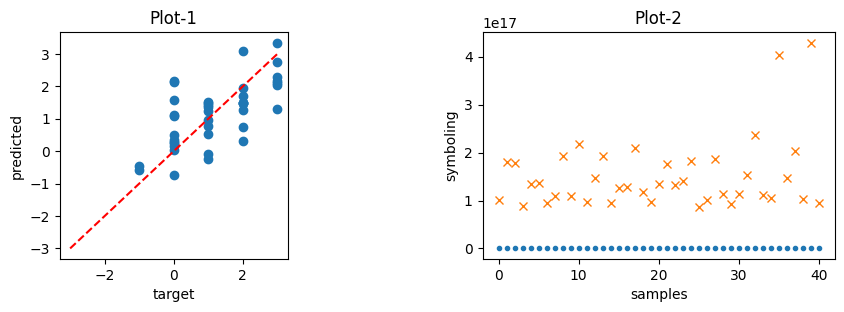

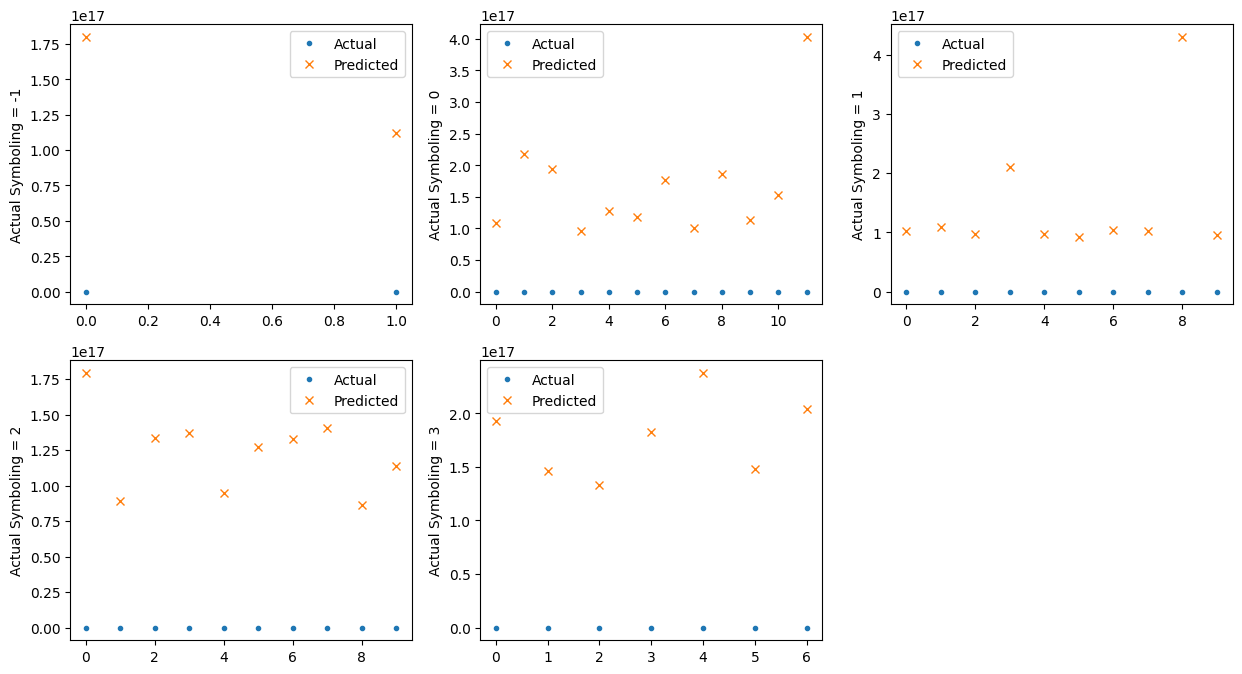

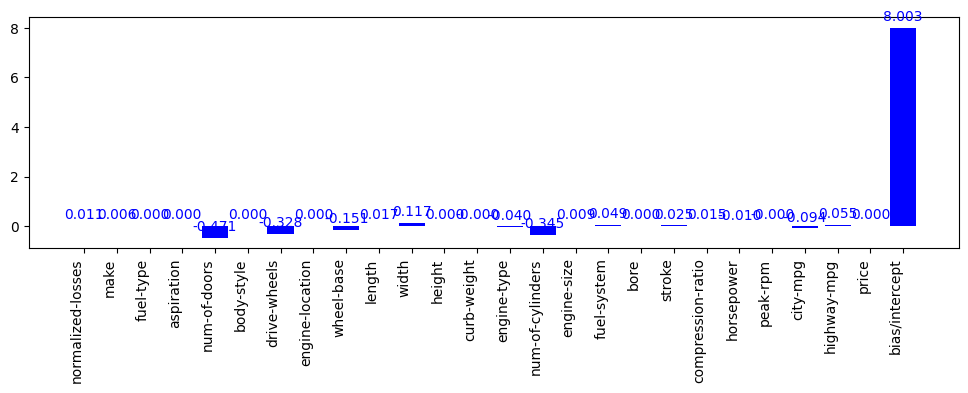

In [59]:
from sklearn import linear_model
from sklearn.linear_model import Lasso

# 1) initialize
lasso_model = linear_model.Lasso(alpha=0.00999, max_iter=100000)
# 2) train the model
lasso_model.fit(X_train, t_train)
# 3) evaluate
test_score = lasso_model.score(X_test, t_test)

print("Test score:  ", test_score)

# 4) Predict the values
y_lasso = lasso_model.predict(X_test)
# 5) Plot actual vs predicted graphs
evaluate(y_lasso, t_test.to_numpy())

# 6) Plot the weights
show_weights(lasso_model, df.columns.values[:-1])

In [52]:
todo_check([
    ('test_score > 0.40', '`test_score` is below .40, try adusting the `alpha` value.')
])

Your code PASSED the code check!


Test score:  0.43659644584363977


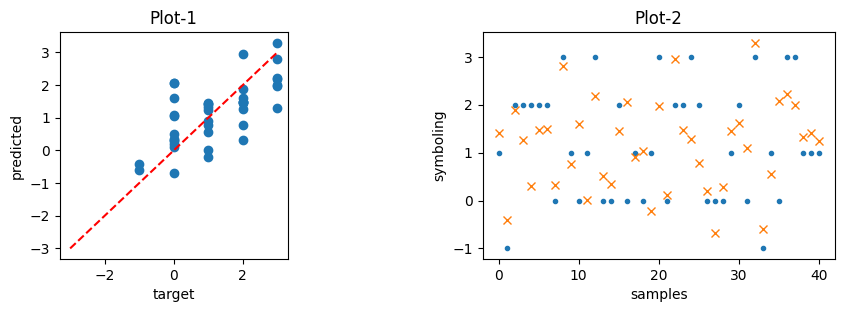

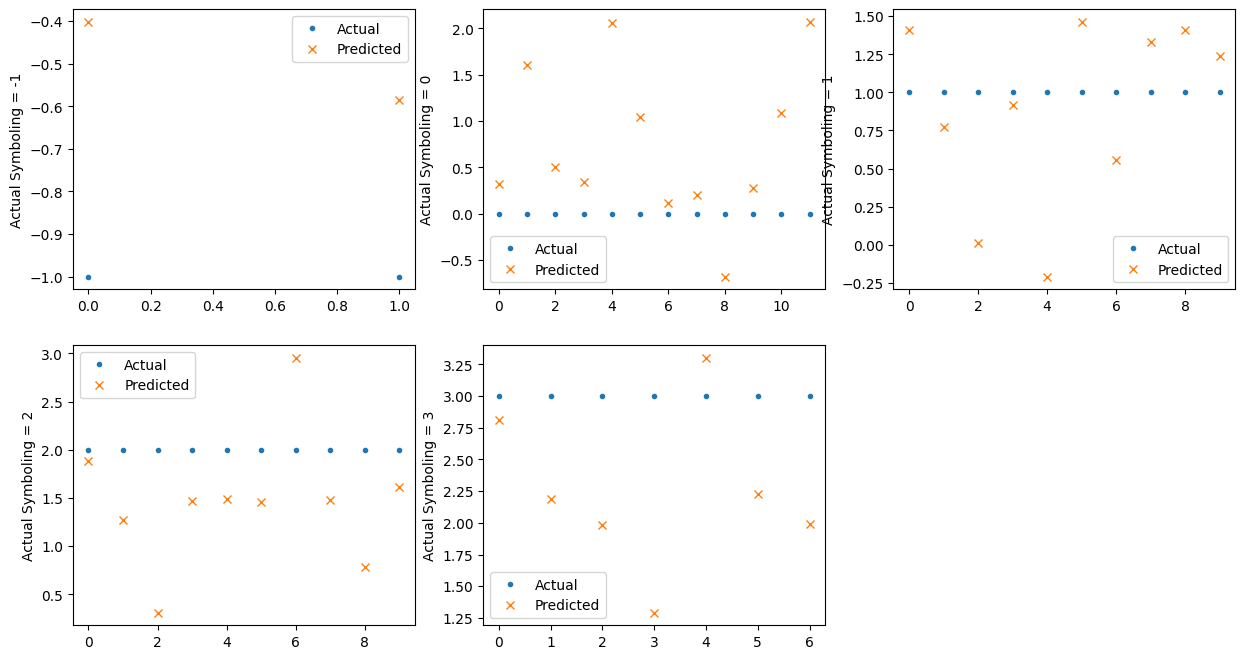

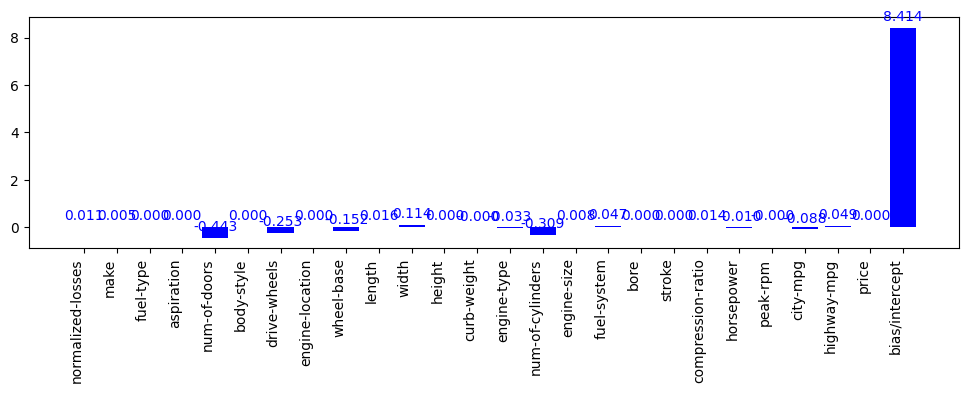

In [53]:
from sklearn.linear_model import ElasticNet

# 1) initialize
model = ElasticNet(alpha=0.02999, max_iter=100000)
# 2) train the model
model.fit(X_train, t_train)
# 3) evaluate
test_score = model.score(X_test, t_test)

print("Test score: ", test_score)

# 4) Predict the values
y = model.predict(X_test)
# 5) Plot actual vs predicted graphs
evaluate(y, t_test.to_numpy())
# 6) Plot the weights
show_weights(model, df.columns.values[:-1])

In [54]:
todo_check([
    ('test_score > 0.40', '`test_score` is below .40, try adusting the `alpha` value.')
])

Your code PASSED the code check!


Test score:  -7.169364985202603e+34


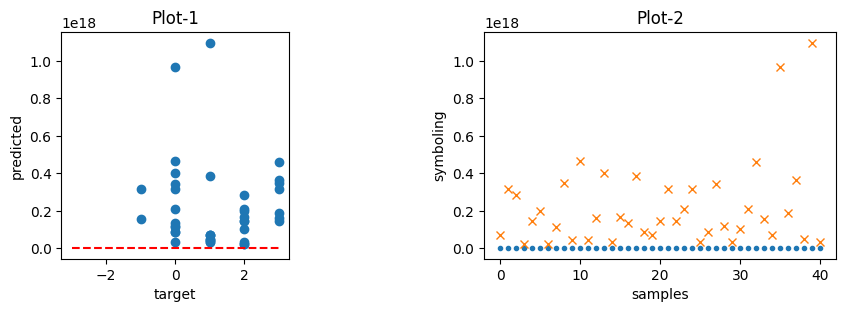

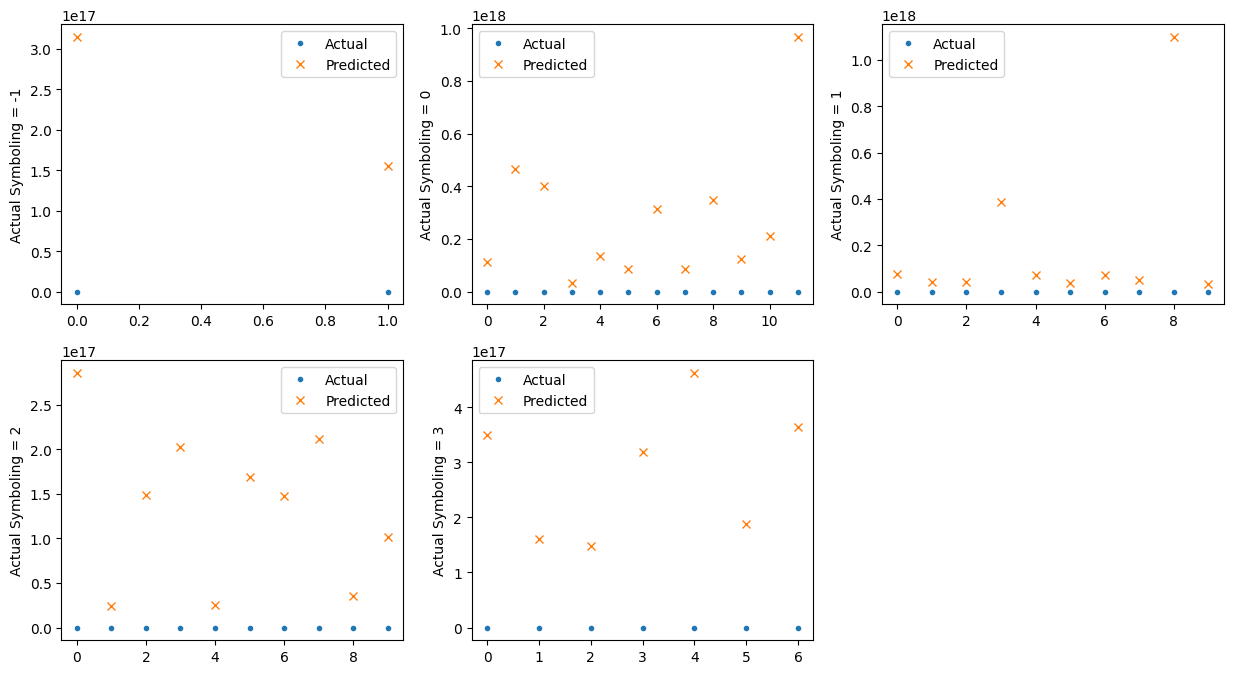

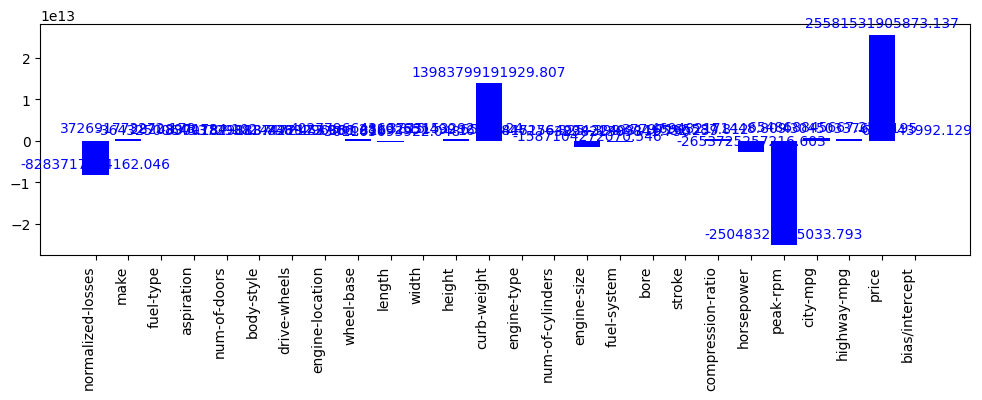

In [64]:
from sklearn.linear_model import SGDRegressor

# 1) initialize
model = SGDRegressor()
# 2) train the model
model.fit(X_train, t_train)
# 3) evaluate
test_score = model.score(X_test, t_test)
print("Test score: ", test_score)

# 4) Predict the values
y = model.predict(X_test)
# 5) Plot actual vs predicted graphs
evaluate(y, t_test.to_numpy())
# 6) Plot the weights
show_weights(model, df.columns.values[:-1])

In [56]:
todo_check([
    ('test_score < 0', '`test_score` should be an extreme negative vaue')
])

Your code PASSED the code check!


In [67]:
%%writefile automobile_linearReg.py


import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn import preprocessing
# TODO: Import all the linear regression models that you used here

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor


# SETTING PAGE CONFIG TO WIDE MODE
st.set_page_config(layout="wide")

# LOADING DATA
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/10/data.csv"
)

"""
# 1985 Auto Imports Database

Abstract: This data set consists of three types of entities: 
        (a) the specification of an auto in terms of various characteristics, 
        (b) its assigned insurance risk rating, 
        (c) its normalized losses in use as compared to other cars. The second rating 
        corresponds to the degree to which the auto is more risky than its price indicates. 
        Cars are initially assigned a risk factor symbol associated with its
        price.   Then, if it is more risky (or less), this symbol is
        adjusted by moving it up (or down) the scale.  Actuarians call this
        process "symboling".  A value of +3 indicates that the auto is
        risky, -3 that it is probably pretty safe.
"""

@st.cache_data
def load_data(nrows):
    # TODO: Import the data, preprocess it, and seperate it into training and testing data
    # Import the data
    df = pd.read_csv(DATA_URL)

    # Preprocess the data (you can add your preprocessing steps here)
    imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
    # Fit the imputer on the data and transform it
    df_freq = pd.DataFrame(imp.fit_transform(df), columns=df.columns)
    df_freq.columns = df.columns
    df = df_freq
    numeric_columns = ['normalized-losses', 'num-of-doors', 'wheel-base', 'length', 'width', 'height','curb-weight', 'num-of-cylinders', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'symboling']

    df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')
    strings_list = ['make', 'fuel-type', 'aspiration', 'body-style', 'drive-wheels', 'engine-location', 'engine-type', 'fuel-system']
    label_encoder = preprocessing.LabelEncoder()
    # Convert each column's string data to integer format
    for column in strings_list:
        df[column] = label_encoder.fit_transform(df[column])
    # Split the data into train and test sets
    # Store the target column 'symboling' into T
    T = df['symboling']
    # Store all the input features into X, excluding the target column 'symboling'
    X = df.drop(columns=['symboling'])
    X_train, X_test, t_train, t_test = train_test_split(X, T, test_size=0.2, random_state=10)
    return df, X_train, X_test, t_train, t_test

df, X_train, X_test, t_train, t_test = load_data(100000)


"## Summary"    
st.dataframe(df.describe())


#################### functions 

def evaluate(y, t):
    fig = plt.figure(figsize=(10,10))
    plt.figure(figsize=(10,10))
    # t vs y plot
    plt.subplot(3,3, 1)
    plt.scatter(t_test, y)
    plt.plot([-3,3], [-3,3], 'r--')
    plt.xlabel("target")
    plt.ylabel("predicted")
    plt.title('Plot-1')
    y = model.predict(X_test)
    # all value comparison
    plt.subplot(3,2, 2)
    # TODO: add the second one
    plt.plot(t_test.to_numpy(), '.')
    plt.plot(y, 'x')
    plt.xlabel("samples")
    plt.ylabel("symboling")
    plt.title('Plot-2')

    # subplots of individual quality comparision
 
    plt.figure(figsize=(10, 8))
    for i, symboling_value in enumerate([-1, 0, 1, 2, 3]):
        plt.subplot(2, 3, i + 1)
        plt.plot(t[t == symboling_value], '.', label='Actual')
        plt.plot(y[t == symboling_value], 'x', label='Predicted')
        plt.ylabel(f'Actual Symboling = {symboling_value}')
        #plt.legend()
        

    #plt.legend()
    
    #plt.tight_layout()
    st.pyplot(fig)
    plt.close(fig)  
# print the value text over the bar
# https://matplotlib.org/3.1.1/gallery/lines_bars_and_markers/barchart.html
def autolabel(ax, rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{:0.3f}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', color='blue')



def show_weights(model, names):
    
    # combine both the coefficients and intercept to present
    w = np.append(model.coef_, model.intercept_)


    fig = plt.figure(figsize=(12,3))
    
    # Paste the corresponding part of your show_weights() function
    names = list(names) + ['bias/intercept']
    

    plt.figure(figsize=(12,3))
    

    # Ensure the lengths match
    names = names[:len(w)]
    rects = plt.bar(range(len(w)), w, color='blue')
    
    ax = plt.gca()
    ax.set_xticks(range(len(w)))
    ax.set_xticklabels(names, rotation = 90, ha='right')
    
   

    autolabel(ax, rects)
    #plt.show()
    
    st.pyplot(fig)
    plt.close(fig)  
####################



# TODO: Add your code to observe different models
# Sidebar for model selection and parameter input
with st.sidebar:
    st.write("## Linear Regression Model?")
    selected_model = st.multiselect(
        "Choose models",
        options=['Least Squares', 'Ridge Regression', 'Lasso Regression', 'Elastic Net', 'Stochastic Gradient Descent'],
        default=['Least Squares']
    )

    ridge_alpha = st.number_input('Ridge Alpha', value=0.5)
    lasso_alpha = st.number_input('Lasso Alpha', value=0.2)
    elasticnet_alpha = st.number_input('Elastic Net Alpha', value=0.1)
    elasticnet_l1_ratio = st.number_input('Elastic Net L1 Ratio', value=0.7)
    sgd_learning_rate = st.number_input('SGD Learning Rate', value=0.3)

#if st.button('Run Models'):
for selected in selected_model:
    if selected == 'Least Squares':
        model = LinearRegression()
    elif selected == 'Ridge Regression':
        model = Ridge(alpha=ridge_alpha)
    elif selected == 'Lasso Regression':
        model = Lasso(alpha=lasso_alpha)
    elif selected == 'Elastic Net':
        model = ElasticNet(alpha=elasticnet_alpha, l1_ratio=elasticnet_l1_ratio)
    elif selected == 'Stochastic Gradient Descent':
        model = ElasticNet(alpha=sgd_learning_rate)
    # Train the model
    model.fit(X_train, t_train)
    test_score = model.score(X_test, t_test)
    #predict the model
    y = model.predict(X_test)
    # Evaluate the model
    evaluate(y, t_test.to_numpy())
    # Show the weights of the model
    show_weights(model, df.columns.values[:-1])                 



Overwriting automobile_linearReg.py
